# Garment Production Intelligence

## 03 — Operational Productivity Analysis

### Objective

Investigate relationships between garment production
performance and operational factors.

### Key Business Questions

1. Is overtime associated with productivity?
2. Does idle time relate to lower productivity?
3. How does workforce size relate to productivity?
4. Does SMV influence production performance?
5. Are style changes associated with productivity?
6. How do incentives relate to productivity?

### Dataset

Cleaned Garment Worker Productivity Dataset.

Source: UCI Machine Learning Repository.

In [155]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Identify project directory
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

# Locate the cleaned dataset
file_path = (
    project_dir
    / "data"
    / "processed"
    / "garments_productivity_cleaned.csv"
)

# Load dataset
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Total records:", df.shape[0])
print("Total columns:", df.shape[1])

df.head()


Dataset loaded successfully!
Total records: 1197
Total columns: 15


,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,2015-01-01,Quarter1,sewing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
1,2015-01-01,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500
2,2015-01-01,Quarter1,sewing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
3,2015-01-01,Quarter1,sewing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
4,2015-01-01,Quarter1,sewing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382


In [156]:

# Select operational productivity variables

operational_columns = [
    "department",
    "team",
    "actual_productivity",
    "targeted_productivity",
    "over_time",
    "idle_time",
    "idle_men",
    "no_of_workers",
    "smv",
    "no_of_style_change",
    "incentive",
    "wip"
]

operational_df = df[operational_columns].copy()

print("Operational dataset shape:", operational_df.shape)

operational_df.head()


Operational dataset shape: (1197, 12)


,department,team,actual_productivity,targeted_productivity,over_time,idle_time,idle_men,no_of_workers,smv,no_of_style_change,incentive,wip
0,sewing,8,0.940725,0.80,7080,0.0,0,59.0,26.16,0,98,1108.0
1,finishing,1,0.886500,0.75,960,0.0,0,8.0,3.94,0,0,NaN
2,sewing,11,0.800570,0.80,3660,0.0,0,30.5,11.41,0,50,968.0
3,sewing,12,0.800570,0.80,3660,0.0,0,30.5,11.41,0,50,968.0
4,sewing,6,0.800382,0.80,1920,0.0,0,56.0,25.90,0,50,1170.0


In [157]:

# Descriptive statistics for operational variables

numeric_columns = [
    "over_time",
    "idle_time",
    "idle_men",
    "no_of_workers",
    "smv",
    "no_of_style_change",
    "incentive",
    "wip",
    "actual_productivity"
]

operational_summary = operational_df[
    numeric_columns
].describe().T

operational_summary.round(2)


,count,mean,std,min,25%,50%,75%,max
over_time,1197.0,4567.46,3348.82,0.00,1440.00,3960.00,6960.00,25920.00
idle_time,1197.0,0.73,12.71,0.00,0.00,0.00,0.00,300.00
idle_men,1197.0,0.37,3.27,0.00,0.00,0.00,0.00,45.00
no_of_workers,1197.0,34.61,22.20,2.00,9.00,34.00,57.00,89.00
smv,1197.0,15.06,10.94,2.90,3.94,15.26,24.26,54.56
no_of_style_change,1197.0,0.15,0.43,0.00,0.00,0.00,0.00,2.00
incentive,1197.0,38.21,160.18,0.00,0.00,0.00,50.00,3600.00
wip,691.0,1190.47,1837.46,7.00,774.50,1039.00,1252.50,23122.00
actual_productivity,1197.0,0.74,0.17,0.23,0.65,0.77,0.85,1.12


## Overtime vs Actual Productivity

### Business Question
Is overtime associated with higher or lower
actual productivity in garment manufacturing?

### Analysis Methods
- Pearson correlation
- Scatter plot
- Department comparison

### Important Note
Correlation does not prove causation.

In [158]:

# Calculate Pearson correlation between overtime and productivity

overtime_correlation = operational_df[
    "over_time"
].corr(
    operational_df["actual_productivity"],
    method="pearson"
)

print("Overtime vs Actual Productivity")
print("-" * 40)

print(
    f"Pearson Correlation: "
    f"{overtime_correlation:.4f}"
)


Overtime vs Actual Productivity
----------------------------------------
Pearson Correlation: -0.0542


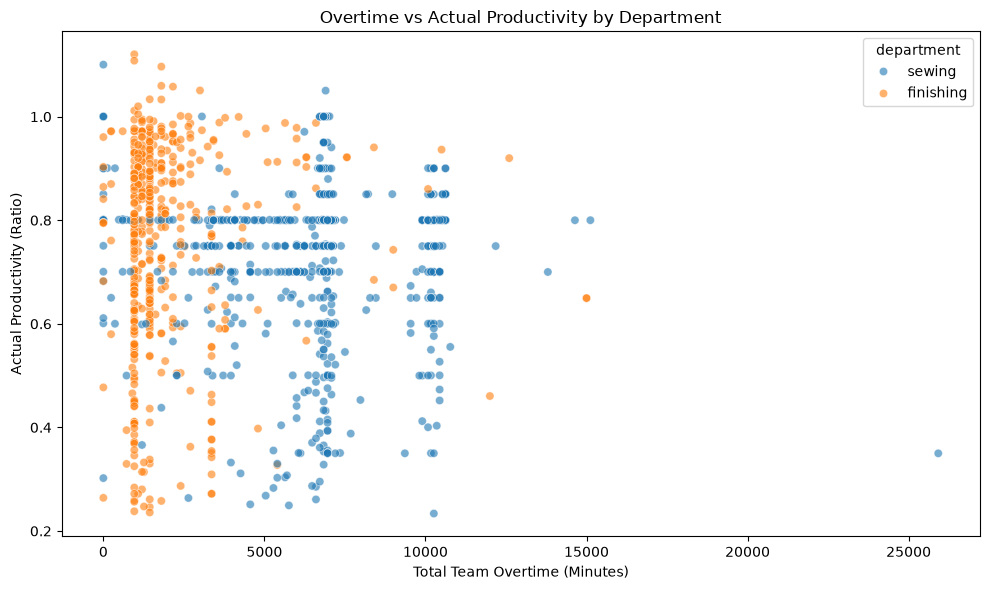

In [159]:

# Visualize overtime and actual productivity

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=operational_df,
    x="over_time",
    y="actual_productivity",
    hue="department",
    alpha=0.6
)

plt.title(
    "Overtime vs Actual Productivity by Department"
)

plt.xlabel("Total Team Overtime (Minutes)")
plt.ylabel("Actual Productivity (Ratio)")

plt.tight_layout()
plt.show()


In [160]:

# Calculate overtime-productivity correlation by department

for department, group in operational_df.groupby("department"):

    correlation = group["over_time"].corr(
        group["actual_productivity"]
    )

    print(
        f"{department.title()}: "
        f"Correlation = {correlation:.4f}"
    )


Finishing: Correlation = 0.0496
Sewing: Correlation = -0.0169


## Idle Time vs Actual Productivity

### Business Question
Is production interruption time associated with
lower actual productivity?

### Objectives
- Calculate idle time correlations.
- Identify how often interruptions occur.
- Compare productivity with and without interruptions.
- Investigate differences between departments.

### Important Note
Correlation does not establish causation.

In [161]:

# Investigate production interruption frequency

total_records = len(operational_df)

idle_records = (operational_df["idle_time"] > 0).sum()

no_idle_records = (
    operational_df["idle_time"] == 0
).sum()

idle_percentage = idle_records / total_records * 100

print("IDLE TIME SUMMARY")
print("-" * 40)

print("Total records:", total_records)
print("Records with idle time:", idle_records)
print("Records without idle time:", no_idle_records)
print(f"Records with interruptions: {idle_percentage:.2f}%")


IDLE TIME SUMMARY
----------------------------------------
Total records: 1197
Records with idle time: 18
Records without idle time: 1179
Records with interruptions: 1.50%


In [162]:

# Calculate idle time vs productivity correlation

idle_corr = operational_df["idle_time"].corr(
    operational_df["actual_productivity"],
    method="pearson"
)

print("Overall Idle Time Correlation:")
print(f"Pearson r = {idle_corr:.4f}")

print("\nCorrelation by Department:")

for department, group in operational_df.groupby("department"):

    if group["idle_time"].nunique() < 2:
        print(
            f"{department.title()}: "
            "Cannot calculate - insufficient variation"
        )
    else:
        corr = group["idle_time"].corr(
            group["actual_productivity"]
        )

        print(f"{department.title()}: r = {corr:.4f}")


Overall Idle Time Correlation:
Pearson r = -0.0809

Correlation by Department:
Finishing: Cannot calculate - insufficient variation
Sewing: r = -0.1137


In [163]:

# Compare productivity for observations with interruptions

idle_comparison = operational_df.copy()

idle_comparison["idle_status"] = np.where(
    idle_comparison["idle_time"] > 0,
    "Interruption",
    "No Interruption"
)

idle_summary = idle_comparison.groupby(
    "idle_status"
).agg(
    total_records=("actual_productivity", "size"),
    avg_productivity=("actual_productivity", "mean")
)

idle_summary["avg_productivity"] *= 100

display(idle_summary.round(2))


,total_records,avg_productivity
idle_status,,
Interruption,18,49.18
No Interruption,1179,73.88


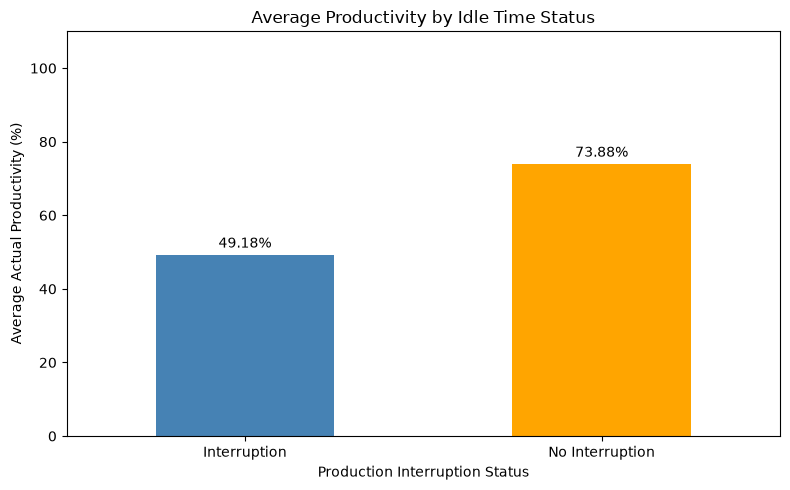

In [164]:

import matplotlib.pyplot as plt

ax = idle_summary["avg_productivity"].plot(
    kind="bar",
    figsize=(8, 5),
    color=["steelblue", "orange"]
)

plt.title("Average Productivity by Idle Time Status")
plt.xlabel("Production Interruption Status")
plt.ylabel("Average Actual Productivity (%)")
plt.xticks(rotation=0)
plt.ylim(0, 110)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()


## Idle Time Analysis by Department

### Objective
Investigate which production departments experienced
interruptions and compare their productivity.

This analysis helps determine whether the overall
productivity difference varies between departments.

In [165]:

# Investigate idle time by department

idle_department = operational_df.copy()

idle_department["has_interruption"] = (
    idle_department["idle_time"] > 0
)

department_idle_summary = idle_department.groupby(
    "department"
).agg(
    total_records=("idle_time", "size"),
    interruption_records=("has_interruption", "sum"),
    avg_idle_time=("idle_time", "mean"),
    avg_productivity=("actual_productivity", "mean")
)

department_idle_summary["interruption_rate"] = (
    department_idle_summary["interruption_records"]
    / department_idle_summary["total_records"] * 100
)

department_idle_summary["avg_productivity"] *= 100

display(department_idle_summary.round(2))


,total_records,interruption_records,avg_idle_time,avg_productivity,interruption_rate
department,,,,,
finishing,506,0,0.00,75.3,0.0
sewing,691,18,1.26,72.2,2.6


In [166]:

# Compare productivity by department and interruption status

idle_department["interruption_status"] = np.where(
    idle_department["has_interruption"],
    "Interruption",
    "No Interruption"
)

department_comparison = idle_department.groupby(
    ["department", "interruption_status"]
).agg(
    records=("actual_productivity", "size"),
    avg_productivity=("actual_productivity", "mean")
).reset_index()

department_comparison["avg_productivity"] *= 100

display(department_comparison.round(2))


,department,interruption_status,records,avg_productivity
0,finishing,No Interruption,506,75.30
1,sewing,Interruption,18,49.18
2,sewing,No Interruption,673,72.82



## Operational Analysis — Business Findings

### Finding 1: Overtime and Productivity

Pearson correlations:

- Finishing: r = 0.0496
- Sewing: r = -0.0169

Both departments showed very weak linear associations
between total team overtime and actual productivity.

Total overtime alone does not explain the differences
in productivity.

### Finding 2: Production Interruptions

The dataset contains 18 observations with recorded
production interruptions.

All 18 observations belong to the sewing department.

Average sewing productivity:

- With interruptions: 49.18%
- Without interruptions: 72.82%

Difference: 23.64 percentage points.

The interrupted group had substantially lower
average productivity.

### Business Recommendations

1. Investigate the reasons for interruptions
   in the sewing department.
2. Monitor interruption frequency and duration.
3. Compare overtime relative to team size.
4. Investigate whether garment complexity, workforce
   size, or other factors explain productivity gaps.

### Limitations

Only 18 sewing observations recorded interruptions.

These findings describe associations in historical
observational data.

They do not establish that interruptions directly
caused lower productivity.


## Workforce Size vs Actual Productivity

### Business Question
Is the number of workers in a production team
associated with actual productivity?

### Objectives
- Measure the relationship using Pearson correlation.
- Compare sewing and finishing departments.
- Visualize workforce size against productivity.
- Identify possible implications for production planning.

In [167]:

# Calculate workforce size vs productivity correlation

workforce_corr = operational_df[
    "no_of_workers"
].corr(
    operational_df["actual_productivity"],
    method="pearson"
)

print("WORKFORCE SIZE VS PRODUCTIVITY")
print("-" * 40)

print(f"Overall Pearson Correlation: {workforce_corr:.4f}")


WORKFORCE SIZE VS PRODUCTIVITY
----------------------------------------
Overall Pearson Correlation: -0.0580


In [168]:

# Workforce-productivity relationship by department

for department, group in operational_df.groupby("department"):

    correlation = group["no_of_workers"].corr(
        group["actual_productivity"]
    )

    print(
        f"{department.title()}: "
        f"Correlation = {correlation:.4f}"
    )


Finishing: Correlation = 0.2740
Sewing: Correlation = 0.0034


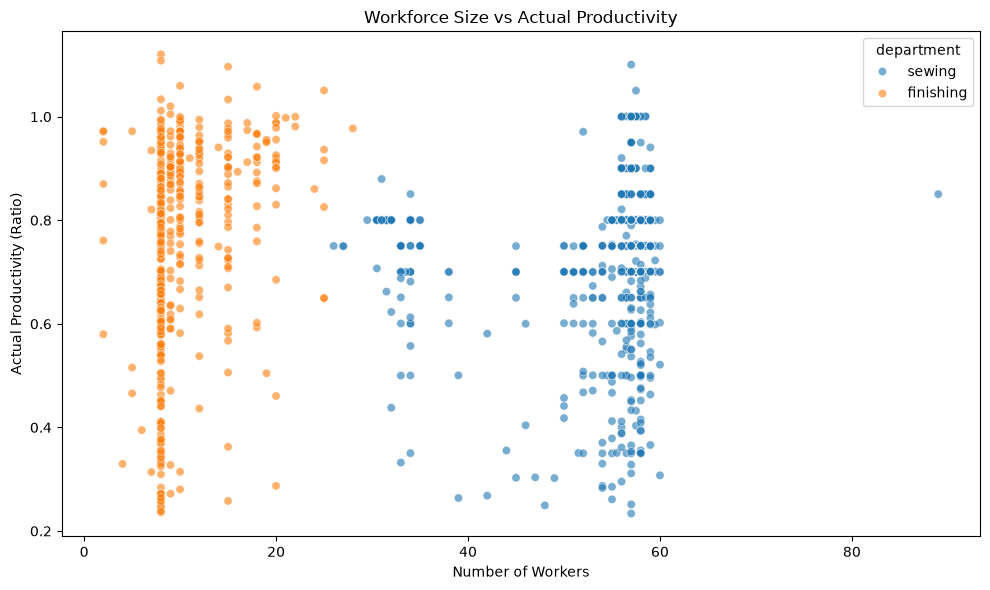

In [169]:

# Visualize workforce size vs actual productivity

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=operational_df,
    x="no_of_workers",
    y="actual_productivity",
    hue="department",
    alpha=0.6
)

plt.title("Workforce Size vs Actual Productivity")
plt.xlabel("Number of Workers")
plt.ylabel("Actual Productivity (Ratio)")

plt.tight_layout()
plt.show()


In [170]:

# Summarize workforce size by department

workforce_summary = operational_df.groupby(
    "department"
).agg(
    total_records=("no_of_workers", "size"),
    avg_workers=("no_of_workers", "mean"),
    min_workers=("no_of_workers", "min"),
    max_workers=("no_of_workers", "max"),
    avg_productivity=("actual_productivity", "mean")
)

workforce_summary["avg_productivity"] *= 100

display(workforce_summary.round(2))


,total_records,avg_workers,min_workers,max_workers,avg_productivity
department,,,,,
finishing,506,10.25,2.0,28.0,75.3
sewing,691,52.45,26.0,89.0,72.2


## Workforce Size Analysis — Final Results

### Objective
Summarize the relationship between workforce size
and actual productivity for each department.

The analysis uses Pearson correlation to measure
linear relationships.

Correlation does not establish causation.

In [171]:

# Final workforce-productivity correlation report

overall_corr = operational_df["no_of_workers"].corr(
    operational_df["actual_productivity"]
)

print("WORKFORCE SIZE VS PRODUCTIVITY")
print("-" * 45)
print(f"Overall correlation: {overall_corr:.4f}")

print("\nDepartment correlations:")

for department, group in operational_df.groupby("department"):

    correlation = group["no_of_workers"].corr(
        group["actual_productivity"]
    )

    print(f"{department.title()}: {correlation:.4f}")

print("\nAverage workers by department:")
print(
    workforce_summary["avg_workers"].round(2)
)


WORKFORCE SIZE VS PRODUCTIVITY
---------------------------------------------
Overall correlation: -0.0580

Department correlations:
Finishing: 0.2740
Sewing: 0.0034

Average workers by department:
department
finishing    10.25
sewing       52.45
Name: avg_workers, dtype: float64



## Workforce Size Analysis — Business Findings

### Correlation Results

- Overall Pearson correlation: -0.0580
- Finishing department: +0.2740
- Sewing department: +0.0034

### Department Workforce Comparison

- Average finishing workforce: 10.25 workers
- Average sewing workforce: 52.45 workers

### Key Findings

1. Overall workforce size has a very weak negative
   linear relationship with actual productivity.

2. The finishing department shows a weak positive
   correlation between workforce size and productivity.

3. The sewing department shows almost no linear
   relationship between workforce size and productivity.

4. Workforce sizes differ substantially between the
   sewing and finishing departments.

### Business Recommendations

- Analyse workforce size separately by department.
- Investigate work allocation and production complexity.
- Monitor productivity together with workforce requirements.
- Examine whether overtime per worker provides more
  meaningful insights than total team overtime.

### Limitations

These findings are based on observational data.

Correlation does not prove that increasing or decreasing
the number of workers will change productivity.

Other factors may influence the observed relationships.


## SMV vs Actual Productivity Analysis

### Business Question
Is Standard Minute Value (SMV) associated with
actual garment production productivity?

### Objectives
- Calculate the correlation between SMV and productivity.
- Compare correlations across departments.
- Visualize the relationship.
- Understand possible implications for production planning.

### Important Note
SMV is the standard time allocated to a task.
Correlation does not establish causation.

In [172]:

# Calculate correlation between SMV and productivity

smv_corr = operational_df["smv"].corr(
    operational_df["actual_productivity"],
    method="pearson"
)

print("SMV VS ACTUAL PRODUCTIVITY")
print("-" * 40)

print(f"Overall Pearson Correlation: {smv_corr:.4f}")


SMV VS ACTUAL PRODUCTIVITY
----------------------------------------
Overall Pearson Correlation: -0.1221


In [173]:

# SMV and productivity correlation by department

for department, group in operational_df.groupby("department"):

    correlation = group["smv"].corr(
        group["actual_productivity"]
    )

    print(
        f"{department.title()}: "
        f"Correlation = {correlation:.4f}"
    )


Finishing: Correlation = 0.2050
Sewing: Correlation = -0.1557


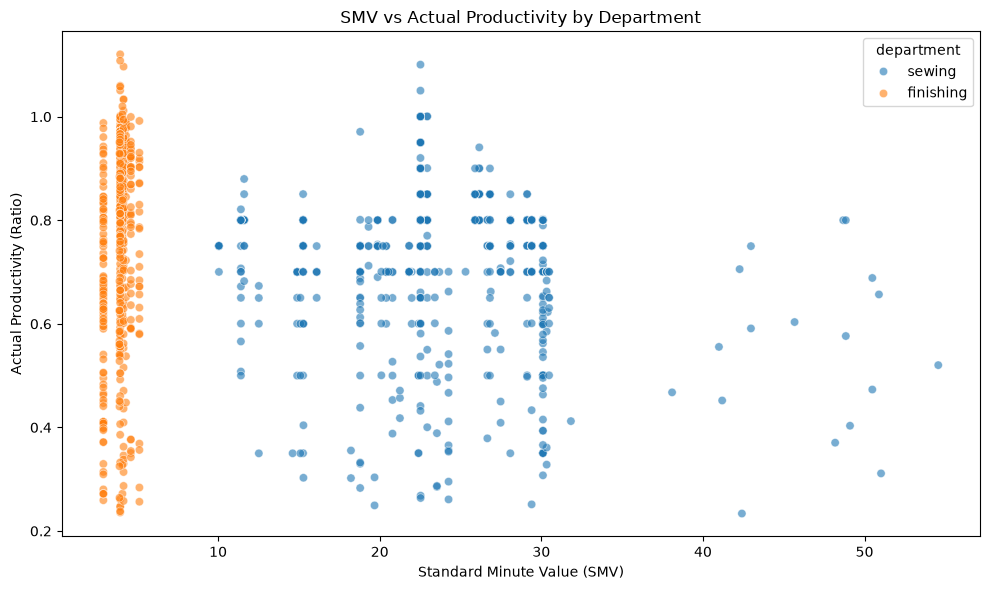

In [174]:

# Visualize SMV vs actual productivity

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=operational_df,
    x="smv",
    y="actual_productivity",
    hue="department",
    alpha=0.6
)

plt.title("SMV vs Actual Productivity by Department")
plt.xlabel("Standard Minute Value (SMV)")
plt.ylabel("Actual Productivity (Ratio)")

plt.tight_layout()
plt.show()


In [175]:

# SMV summary by department

smv_summary = operational_df.groupby(
    "department"
).agg(
    total_records=("smv", "size"),
    avg_smv=("smv", "mean"),
    min_smv=("smv", "min"),
    max_smv=("smv", "max"),
    avg_productivity=("actual_productivity", "mean")
)

smv_summary["avg_productivity"] *= 100

display(smv_summary.round(2))


,total_records,avg_smv,min_smv,max_smv,avg_productivity
department,,,,,
finishing,506,3.89,2.90,5.13,75.3
sewing,691,23.25,10.05,54.56,72.2


In [176]:

# Final SMV and productivity correlation report

overall_smv_corr = operational_df["smv"].corr(
    operational_df["actual_productivity"]
)

print("SMV VS PRODUCTIVITY")
print("-" * 45)

print(f"Overall correlation: {overall_smv_corr:.4f}")

print("\nDepartment correlations:")

for department, group in operational_df.groupby("department"):

    correlation = group["smv"].corr(
        group["actual_productivity"]
    )

    print(f"{department.title()}: {correlation:.4f}")

print("\nAverage SMV by department:")
print(smv_summary["avg_smv"].round(2))


SMV VS PRODUCTIVITY
---------------------------------------------
Overall correlation: -0.1221

Department correlations:
Finishing: 0.2050
Sewing: -0.1557

Average SMV by department:
department
finishing     3.89
sewing       23.25
Name: avg_smv, dtype: float64


## SMV Analysis — Business Findings

### Objective
Investigate the relationship between Standard Minute
Value (SMV) and actual garment productivity.

### Department Comparison

- Average SMV in finishing: 3.89
- Average SMV in sewing: 23.25

Sewing has considerably higher standard task-time
requirements than finishing.

### Correlation Findings

The overall and department-specific correlation
coefficients will be interpreted after reviewing
the calculated results.

### Limitations

SMV measures allocated standard time, not garment
complexity directly.

Correlation does not establish causation.

In [177]:

# Final SMV correlation summary

print("SMV VS PRODUCTIVITY")
print("-" * 40)

overall_corr = operational_df["smv"].corr(
    operational_df["actual_productivity"]
)

print(f"Overall correlation: {overall_corr:.4f}")

for department, group in operational_df.groupby("department"):
    corr = group["smv"].corr(
        group["actual_productivity"]
    )

    print(f"{department.title()}: {corr:.4f}")


SMV VS PRODUCTIVITY
----------------------------------------
Overall correlation: -0.1221
Finishing: 0.2050
Sewing: -0.1557


### SMV Analysis — Business Interpretation

The sewing department has a higher average SMV
(23.25) than the finishing department (3.89).

This indicates differences in standard task-time
requirements between departments.

The overall correlation and department-specific
correlations should be considered separately.

SMV is a measure of allocated task time and should
not be treated as a direct measure of complexity.

Correlation does not establish causation.


### SMV Analysis — Business Interpretation

#### Correlation Results

- Overall Pearson correlation: -0.1221
- Finishing department: +0.2050
- Sewing department: -0.1557

#### Department Comparison

- Average SMV in finishing: 3.89
- Average SMV in sewing: 23.25

#### Key Findings

1. The overall relationship between SMV and actual
   productivity is weakly negative.

2. The finishing department shows a weak positive
   association between SMV and productivity.

3. The sewing department shows a weak negative
   association between SMV and productivity.

4. Sewing and finishing have substantially different
   standard task-time requirements.

#### Business Recommendations

- Analyse SMV and productivity separately by department.
- Investigate whether high-SMV tasks require different
  production planning and resource allocation.
- Compare productivity across groups with similar SMV.
- Consider workforce size, overtime and other operational
  factors in further statistical analysis.

#### Limitations

SMV represents the standard time allocated to a task
and is not a direct measurement of garment complexity.

These relationships are observational and do not
establish causation.


## Garment Style Changes vs Productivity

### Business Question
Are garment style changes associated with lower
actual productivity?

### Objectives
- Examine the frequency of style changes.
- Compare productivity across different numbers
  of style changes.
- Investigate differences between departments.
- Visualize the relationship.

### Important Note
An observed relationship does not prove causation.

In [178]:

# Check frequency of garment style changes

style_counts = (
    operational_df["no_of_style_change"]
    .value_counts()
    .sort_index()
)

print("GARMENT STYLE CHANGE FREQUENCY")
print("-" * 40)

print(style_counts)


GARMENT STYLE CHANGE FREQUENCY
----------------------------------------
no_of_style_change
0    1050
1     114
2      33
Name: count, dtype: int64


In [179]:

# Calculate productivity by number of style changes

style_summary = operational_df.groupby(
    "no_of_style_change"
).agg(
    total_records=("actual_productivity", "size"),
    avg_productivity=("actual_productivity", "mean"),
    avg_target=("targeted_productivity", "mean")
).reset_index()

# Convert productivity ratios into percentages
style_summary["avg_productivity"] *= 100
style_summary["avg_target"] *= 100

# Calculate productivity gap
style_summary["productivity_gap_pp"] = (
    style_summary["avg_productivity"]
    - style_summary["avg_target"]
)

display(style_summary.round(2))


,no_of_style_change,total_records,avg_productivity,avg_target,productivity_gap_pp
0,0,1050,75.04,73.83,1.21
1,1,114,61.50,66.18,-4.68
2,2,33,66.19,68.79,-2.59


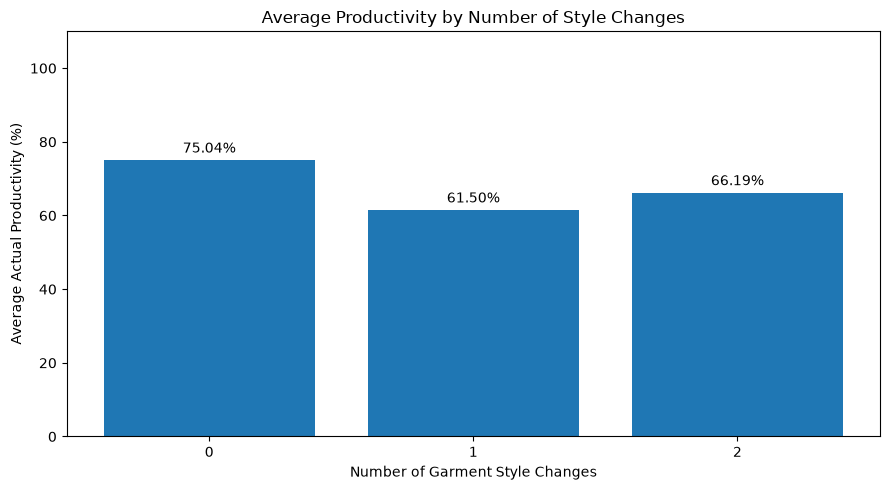

In [180]:

import matplotlib.pyplot as plt

# Create bar chart
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    style_summary["no_of_style_change"].astype(str),
    style_summary["avg_productivity"]
)

# Add percentage labels
ax.bar_label(
    bars,
    fmt="%.2f%%",
    padding=3
)

plt.title("Average Productivity by Number of Style Changes")
plt.xlabel("Number of Garment Style Changes")
plt.ylabel("Average Actual Productivity (%)")

plt.ylim(0, max(110, style_summary["avg_productivity"].max() + 10))
plt.tight_layout()
plt.show()


In [181]:

# Compare style changes across departments

style_department_summary = operational_df.groupby(
    ["department", "no_of_style_change"]
).agg(
    records=("actual_productivity", "size"),
    avg_productivity=("actual_productivity", "mean")
).reset_index()

style_department_summary["avg_productivity"] *= 100

display(style_department_summary.round(2))


,department,no_of_style_change,records,avg_productivity
0,finishing,0,506,75.30
1,sewing,0,544,74.81
2,sewing,1,114,61.50
3,sewing,2,33,66.19


In [182]:

# Final garment style-change analysis report

print("GARMENT STYLE CHANGE ANALYSIS")
print("-" * 45)

print("\nOverall style-change summary:")
display(style_summary.round(2))

print("\nStyle changes by department:")
display(style_department_summary.round(2))

# Calculate correlation
style_corr = operational_df["no_of_style_change"].corr(
    operational_df["actual_productivity"]
)

print(f"\nOverall Pearson Correlation: {style_corr:.4f}")

# Department-specific correlations
print("\nDepartment correlations:")

for department, group in operational_df.groupby("department"):

    if group["no_of_style_change"].nunique() < 2:
        print(f"{department.title()}: Not defined (no variation)")
    else:
        corr = group["no_of_style_change"].corr(
            group["actual_productivity"]
        )
        print(f"{department.title()}: {corr:.4f}")


GARMENT STYLE CHANGE ANALYSIS
---------------------------------------------

Overall style-change summary:


,no_of_style_change,total_records,avg_productivity,avg_target,productivity_gap_pp
0,0,1050,75.04,73.83,1.21
1,1,114,61.50,66.18,-4.68
2,2,33,66.19,68.79,-2.59



Style changes by department:


,department,no_of_style_change,records,avg_productivity
0,finishing,0,506,75.30
1,sewing,0,544,74.81
2,sewing,1,114,61.50
3,sewing,2,33,66.19



Overall Pearson Correlation: -0.2074

Department correlations:
Finishing: Not defined (no variation)
Sewing: -0.2817



## Style Change Analysis — Business Findings

### Productivity Comparison

- No style changes: 75.04% average productivity
- One style change: 61.50% average productivity
- Two style changes: 66.19% average productivity

### Key Findings

1. Observations without style changes had the
   highest average actual productivity.

2. One style change was associated with a
   13.54 percentage-point lower average
   productivity than no style changes.

3. Two style changes were associated with an
   8.85 percentage-point lower average
   productivity than no style changes.

4. The relationship was not strictly decreasing,
   so further investigation is necessary.

### Business Recommendations

- Monitor productivity during garment style changes.
- Investigate setup and adjustment time.
- Compare style-change performance within departments.
- Examine whether task requirements, workforce size,
  or overtime are associated with these differences.

### Limitations

The analysis uses observational data.

Different style-change groups may contain different
numbers of production observations.

The results do not prove that style changes directly
caused lower productivity.


In [183]:

# Final style-change verification

print("STYLE CHANGE COUNTS")
print(operational_df["no_of_style_change"].value_counts().sort_index())

print("\nPRODUCTIVITY BY STYLE CHANGE")
display(style_summary.round(2))

print("\nSTYLE CHANGE CORRELATIONS")

overall_corr = operational_df["no_of_style_change"].corr(
    operational_df["actual_productivity"]
)

print(f"Overall: {overall_corr:.4f}")

for department, group in operational_df.groupby("department"):
    if group["no_of_style_change"].nunique() < 2:
        print(f"{department.title()}: Not defined")
    else:
        corr = group["no_of_style_change"].corr(
            group["actual_productivity"]
        )
        print(f"{department.title()}: {corr:.4f}")


STYLE CHANGE COUNTS
no_of_style_change
0    1050
1     114
2      33
Name: count, dtype: int64

PRODUCTIVITY BY STYLE CHANGE


,no_of_style_change,total_records,avg_productivity,avg_target,productivity_gap_pp
0,0,1050,75.04,73.83,1.21
1,1,114,61.50,66.18,-4.68
2,2,33,66.19,68.79,-2.59



STYLE CHANGE CORRELATIONS
Overall: -0.2074
Finishing: Not defined
Sewing: -0.2817



### Final Style Change Analysis — Key Findings

#### Observation Counts
- No style changes: 1,050 records
- One style change: 114 records
- Two style changes: 33 records

#### Correlation Results
- Overall Pearson correlation: -0.2074
- Sewing department: -0.2817
- Finishing department: Not defined (no variation)

#### Business Interpretation
Production observations with style changes generally
recorded lower average productivity than those
without style changes.

The sewing department shows a weak negative linear
association between style changes and productivity.

The finishing department recorded no variation in
style-change counts, so its correlation is undefined.

#### Recommendations
1. Monitor sewing productivity during style changes.
2. Investigate production setup and adjustment time.
3. Compare productivity across similar garment tasks.
4. Investigate whether workforce size, SMV, or
   overtime contribute to the observed differences.

#### Limitations
The two-style-change group contains only 33 records.

The results are observational and do not establish
that style changes cause reduced productivity.


## Incentives vs Actual Productivity

### Business Question
Are financial incentives associated with higher
garment production productivity?

### Objectives
- Examine the distribution of incentives.
- Compare productivity across incentive levels.
- Calculate overall and department-specific correlations.
- Visualize the incentive-productivity relationship.

### Important Note
Incentives are recorded in Bangladeshi Taka (BDT).

Correlation does not prove that incentives cause
higher productivity. Incentives may also be awarded
based on achieved performance.

In [184]:

# Examine financial incentive distribution

print("INCENTIVE DISTRIBUTION")
print("-" * 40)

print(operational_df["incentive"].describe())

print("\nRecords with zero incentives:")
print((operational_df["incentive"] == 0).sum())

print("\nRecords with positive incentives:")
print((operational_df["incentive"] > 0).sum())

print("\nMost common incentive amounts:")
print(
    operational_df["incentive"]
    .value_counts()
    .head(10)
)


INCENTIVE DISTRIBUTION
----------------------------------------
count    1197.000000
mean       38.210526
std       160.182643
min         0.000000
25%         0.000000
50%         0.000000
75%        50.000000
max      3600.000000
Name: incentive, dtype: float64

Records with zero incentives:
604

Records with positive incentives:
593

Most common incentive amounts:
incentive
0     604
50    113
63     61
45     54
30     52
23     38
38     29
60     28
40     27
75     24
Name: count, dtype: int64


In [185]:

# Compare productivity based on incentive status

incentive_df = operational_df.copy()

incentive_df["incentive_status"] = np.where(
    incentive_df["incentive"] > 0,
    "Received Incentive",
    "No Incentive"
)

incentive_summary = incentive_df.groupby(
    "incentive_status"
).agg(
    total_records=("actual_productivity", "size"),
    avg_productivity=("actual_productivity", "mean"),
    avg_incentive=("incentive", "mean")
)

incentive_summary["avg_productivity"] *= 100

display(incentive_summary.round(2))


,total_records,avg_productivity,avg_incentive
incentive_status,,,
No Incentive,604,71.26,0.00
Received Incentive,593,75.80,77.13


In [186]:

# Calculate incentive-productivity correlation

incentive_corr = operational_df["incentive"].corr(
    operational_df["actual_productivity"],
    method="pearson"
)

print("INCENTIVES VS PRODUCTIVITY")
print("-" * 40)

print(f"Overall Pearson Correlation: {incentive_corr:.4f}")


INCENTIVES VS PRODUCTIVITY
----------------------------------------
Overall Pearson Correlation: 0.0765


In [187]:

# Incentive-productivity correlation by department

print("DEPARTMENT CORRELATIONS")
print("-" * 40)

for department, group in operational_df.groupby("department"):

    if group["incentive"].nunique() < 2:
        print(
            f"{department.title()}: "
            "Not defined (no incentive variation)"
        )
    else:
        correlation = group["incentive"].corr(
            group["actual_productivity"]
        )

        print(
            f"{department.title()}: "
            f"{correlation:.4f}"
        )


DEPARTMENT CORRELATIONS
----------------------------------------
Finishing: 0.0133
Sewing: 0.8041


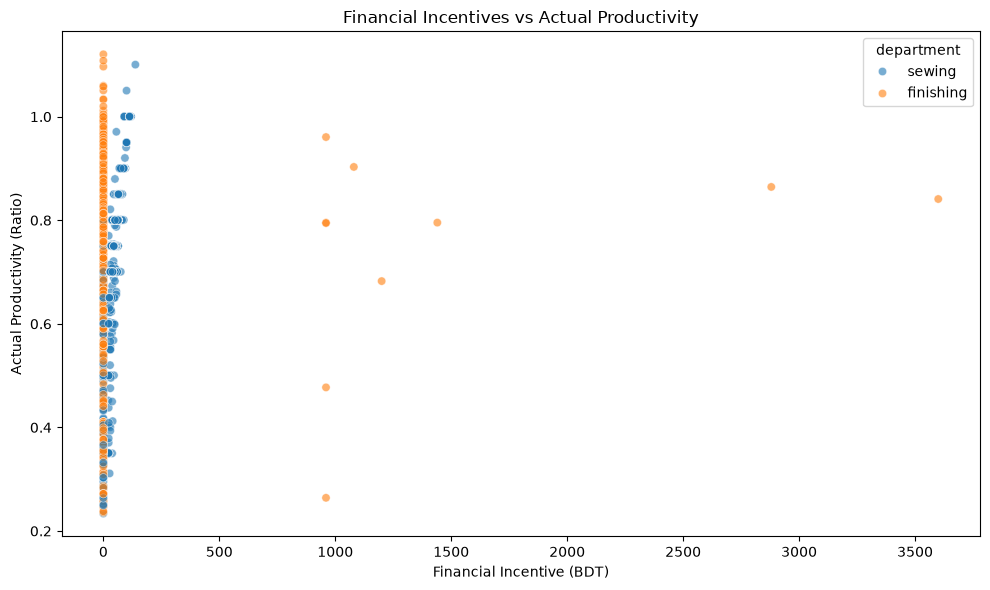

In [188]:

# Incentives vs actual productivity visualization

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=operational_df,
    x="incentive",
    y="actual_productivity",
    hue="department",
    alpha=0.6
)

plt.title("Financial Incentives vs Actual Productivity")
plt.xlabel("Financial Incentive (BDT)")
plt.ylabel("Actual Productivity (Ratio)")

plt.tight_layout()
plt.show()


## Incentive Distribution and Outlier Investigation

### Objective
Investigate unusually high financial incentives
and examine their relationship with productivity.

### Important Considerations
- Incentive amounts are measured in BDT.
- Extreme values should be investigated before removal.
- Correlation does not establish causation.

In [189]:

# Investigate high incentive amounts

print("INCENTIVE DISTRIBUTION")
print("-" * 45)

print(operational_df["incentive"].describe())

print("\nIncentive percentiles:")
print(
    operational_df["incentive"].quantile(
        [0.50, 0.90, 0.95, 0.99, 1.00]
    )
)

print("\n10 highest incentive observations:")

highest_incentives = operational_df.nlargest(
    10, "incentive"
)

display(
    highest_incentives[
        [
            "department",
            "team",
            "incentive",
            "actual_productivity"
        ]
    ]
)



INCENTIVE DISTRIBUTION
---------------------------------------------
count    1197.000000
mean       38.210526
std       160.182643
min         0.000000
25%         0.000000
50%         0.000000
75%        50.000000
max      3600.000000
Name: incentive, dtype: float64

Incentive percentiles:
0.50       0.0
0.90      63.0
0.95      88.0
0.99     119.0
1.00    3600.0
Name: incentive, dtype: float64

10 highest incentive observations:


,department,team,incentive,actual_productivity
1133,finishing,9,3600,0.841000
1130,finishing,5,2880,0.864343
1137,finishing,3,1440,0.795417
1143,finishing,2,1200,0.682500
1129,finishing,12,1080,0.902963
1128,finishing,11,960,0.960625
1138,finishing,4,960,0.795388
1139,finishing,1,960,0.794567
1148,finishing,10,960,0.477292
1149,finishing,8,960,0.264062


In [190]:

# Final incentive-productivity correlation report

print("INCENTIVES VS PRODUCTIVITY")
print("-" * 45)

overall_corr = operational_df["incentive"].corr(
    operational_df["actual_productivity"]
)

print(f"Overall Pearson correlation: {overall_corr:.4f}")

print("\nDepartment correlations:")

for department, group in operational_df.groupby("department"):

    if group["incentive"].nunique() < 2:
        print(
            f"{department.title()}: "
            "Not defined (no variation)"
        )
    else:
        corr = group["incentive"].corr(
            group["actual_productivity"]
        )

        print(f"{department.title()}: {corr:.4f}")


INCENTIVES VS PRODUCTIVITY
---------------------------------------------
Overall Pearson correlation: 0.0765

Department correlations:
Finishing: 0.0133
Sewing: 0.8041


In [191]:

# Compare incentive status by department

incentive_comparison = operational_df.copy()

incentive_comparison["incentive_status"] = np.where(
    incentive_comparison["incentive"] > 0,
    "Positive Incentive",
    "Zero Incentive"
)

department_incentive_summary = incentive_comparison.groupby(
    ["department", "incentive_status"]
).agg(
    records=("actual_productivity", "size"),
    avg_productivity=("actual_productivity", "mean"),
    avg_incentive=("incentive", "mean")
).reset_index()

department_incentive_summary["avg_productivity"] *= 100

display(department_incentive_summary.round(2))


,department,incentive_status,records,avg_productivity,avg_incentive
0,finishing,Positive Incentive,10,73.78,1500.00
1,finishing,Zero Incentive,496,75.33,0.00
2,sewing,Positive Incentive,583,75.84,52.72
3,sewing,Zero Incentive,108,52.58,0.00


In [192]:

# Final incentive analysis summary

print("INCENTIVE ANALYSIS - FINAL RESULTS")
print("-" * 45)

print("\nOverall Pearson Correlation:")
print(
    round(
        operational_df["incentive"].corr(
            operational_df["actual_productivity"]
        ), 4
    )
)

print("\nDepartment Correlations:")

for department, group in operational_df.groupby("department"):
    correlation = group["incentive"].corr(
        group["actual_productivity"]
    )
    print(f"{department.title()}: {correlation:.4f}")

print("\nIncentive Percentiles (BDT):")
print(
    operational_df["incentive"].quantile(
        [0.50, 0.90, 0.95, 0.99, 1.00]
    )
)


INCENTIVE ANALYSIS - FINAL RESULTS
---------------------------------------------

Overall Pearson Correlation:
0.0765

Department Correlations:
Finishing: 0.0133
Sewing: 0.8041

Incentive Percentiles (BDT):
0.50       0.0
0.90      63.0
0.95      88.0
0.99     119.0
1.00    3600.0
Name: incentive, dtype: float64


In [193]:

# Sensitivity analysis using the 99th percentile

limit = operational_df["incentive"].quantile(0.99)

below_limit = operational_df[
    operational_df["incentive"] <= limit
]

print("99th percentile incentive:", limit)
print("Records in sensitivity analysis:", len(below_limit))

print("Pearson r using all records:",
      round(operational_df["incentive"].corr(
          operational_df["actual_productivity"]
      ), 4))

print("Pearson r excluding top 1% incentive values:",
      round(below_limit["incentive"].corr(
          below_limit["actual_productivity"]
      ), 4))


99th percentile incentive: 119.0
Records in sensitivity analysis: 1186
Pearson r using all records: 0.0765
Pearson r excluding top 1% incentive values: 0.3091



## Incentive Analysis — Business Findings

### 1. Incentive and Productivity Relationship

Overall Pearson correlation using all records:
r = +0.0765

Pearson correlation excluding incentive values
above the 99th percentile:
r = +0.3091

The relationship is very weak when all observations
are included and moderately positive in the
restricted sensitivity-analysis sample.

### 2. Extreme Incentive Values

- 99th percentile incentive: 119 BDT
- Original observations: 1,197
- Sensitivity-analysis observations: 1,186
- Excluded observations: 11

Extreme incentive values substantially influence
the overall Pearson correlation.

These observations are not automatically errors
and should not be deleted without investigation.

### 3. Department Comparison

Sewing:
- Positive incentive: 583 observations
- Average productivity with incentive: 75.84%
- Zero incentive: 108 observations
- Average productivity without incentive: 52.58%

Finishing:
- Positive incentive: 10 observations
- Average productivity with incentive: 73.78%
- Zero incentive: 496 observations
- Average productivity without incentive: 75.33%

### 4. Business Recommendations

1. Investigate unusually large incentive payments.
2. Analyse incentive patterns separately by department.
3. Examine whether incentives are awarded based
   on achieved productivity.
4. Consider other operational factors before
   recommending changes to incentive policies.
5. Use sensitivity analysis when reporting
   correlations influenced by extreme values.

### 5. Limitations

The data is observational.

Incentive payments may be related to already
achieved productivity.

Correlation does not establish causation.

The sensitivity analysis excludes 11 observations
only to investigate statistical sensitivity.
The original dataset remains unchanged.
